# Highlight Table (heat-shaded table)

**Family:** Magnitude &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Magnitude:* Compare sizes, relative or absolute (usually counts rather than rates).

## Design purpose

A table of numbers with each cell shaded by its value. Readers can look up exact values and still see high and low cells at a glance, which makes it a bridge between a table and a heatmap.

## When to use

- Readers need exact numbers and patterns (finance reports, cross-tabs)
- Compare values across two categorical dimensions (product × month)

## Avoid when

- The table is huge (use a pure heatmap)
- Rows have very different scales (shade per row or normalise first)

## Alternatives

- Heatmap
- Grouped bar chart

## Design tips

- Use a single-hue sequential scale; switch text to white on dark cells

## Example

Units sold by product and month (simulated).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(23)
products = ["Laptops", "Tablets", "Phones", "Monitors", "Headsets", "Keyboards"]
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
base = np.array([120, 80, 300, 90, 150, 60])[:, None]
season = np.array([0.9, 0.85, 1.0, 1.05, 1.1, 1.25])[None, :]
df = pd.DataFrame((base * season * rng.uniform(0.85, 1.15, (6, 6))).round().astype(int),
                  index=products, columns=months)
df

,Jan,Feb,Mar,Apr,May,Jun
Laptops,114,106,107,111,138,166
Tablets,66,62,85,83,86,95
Phones,235,252,282,305,334,396
Monitors,84,82,77,99,100,124
Headsets,153,109,165,146,171,202
Keyboards,60,58,62,70,66,69


### Plot

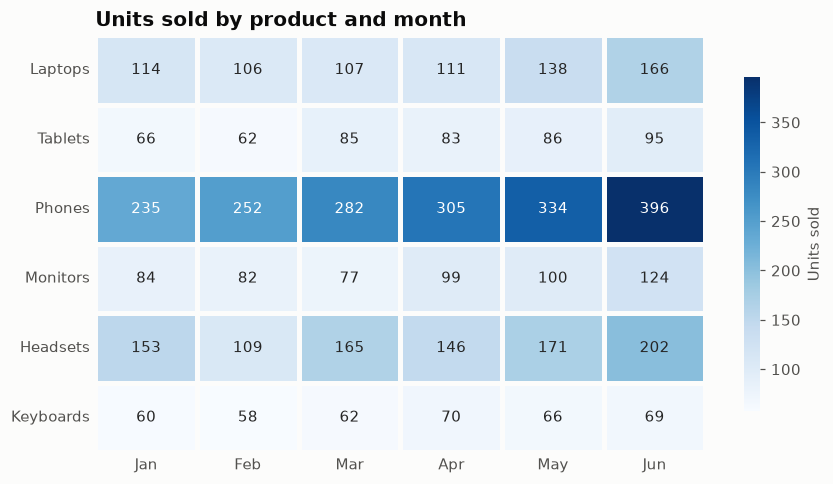

In [3]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(df, annot=True, fmt="d", cmap=SEQ_CMAP, linewidths=2, linecolor="#fcfcfb",
            cbar_kws={"label": "Units sold", "shrink": 0.8}, ax=ax, annot_kws={"fontsize": 10})
ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(length=0)
ax.set_title("Units sold by product and month")
fig.tight_layout()
plt.show()

## How to read it

Read the exact number in each cell; darker blue means more units. Phones dominate and rise every month to 396 in June, and every product except Keyboards has its best month in June.

---
Standalone script: [`highlight_table.py`](highlight_table.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)